In [1]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
np.set_printoptions(legacy='1.21')

In [2]:
#Functions defines in previous classes

#Present values of a sum to be paid in n periods, discrete time
def pvdiscr(FV,r,n):
    return FV/((1+r)**n)

#Present values of a sum to be paid at T, continuous time
def pvcts(FV,r,T):
    return FV*np.exp(-r*T)

#Present values of a perpetuity with coupon C
def pvperp(C,r):
    return C/r

#Present value of paying C each period for N periods.
def pvann(C,r,N):
    return (C/r)*(1- (1/(1+r))**N)

#Alternative formula for an annuity.
def pvann2(C,r,N):
    p=[C/(1+r)**i for i in range(1,N+1)]
    return sum(p)

#Let r be the annual percentage rate (APR)
#Definition of Effective Annual Rate with k payments per year
def ear(r,k):
    y=(1+(r/k))**k-1
    return y

#Price of a bond
def bondprice(C,FV,r,N):
    return pvann2(C,r,N)+FV/(1+r)**N

#Annuity with less-than-annual payments
def pvannk(C,k,r,N):
    p=[(C/k)/(1+(ear(r,k)/k))**i for i in range(1,N*k+1)]
    return sum(p)

#The price of a bond when coupons are paid k times per year and r is APR
def bondpricek(C,k,FV,r,N):
    return pvannk(C,k,r,N)+FV/(1+ear(r,k)/k)**(N*k)

#Forward value of an annuity
def fwann(C,r,N):
    return pvann2(C,r,N)*((1+r)**N)

#Alternative way to compute forward value.
def fwann2(C,r,N):
    p=[C*(1+r)**i for i in range(0,N)]
    return sum(p)

#Finding the YTM of a bond
def YTM(C,FV,N,P,guess):
    def equation1(x):
        return bondprice(C,FV,x,N) - P
    return fsolve(equation1,guess)

In [3]:
# The term structure of interest rates shows the different interest rates 
# for different maturities. Here is an example
maturity = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
rates = np.array([
    0.040, 0.041, 0.042, 0.043, 0.044,
    0.045, 0.046, 0.047, 0.048, 0.048])

In [4]:
#Put the data in a dataframe using the Panda command.
yield_curve = pd.DataFrame({'Maturity': maturity,'Zero Rate': rates})
print(yield_curve)

   Maturity  Zero Rate
0      0.25      0.040
1      0.50      0.041
2      1.00      0.042
3      2.00      0.043
4      3.00      0.044
5      5.00      0.045
6      7.00      0.046
7     10.00      0.047
8     20.00      0.048
9     30.00      0.048


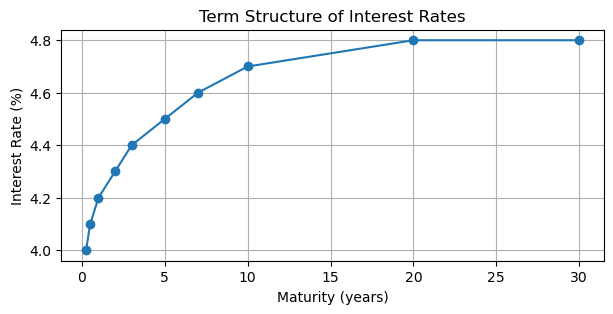

In [5]:
#A picture of the term structure just entered
plt.figure(figsize=(7, 3))
plt.plot(maturity, rates * 100, marker='o')
plt.xlabel('Maturity (years)')
plt.ylabel('Interest Rate (%)')
plt.title('Term Structure of Interest Rates')
plt.grid(True)
plt.show()

In [6]:
# Spot rates are computed, in principle, looking at zero-coupon bonds
# To each rate correspond a discount factor.
# Here we use the discount factor using continuous compounding discount
#according to the formula DF(T) = exp(-r(T) * T)
discount_factor = np.exp(-rates * maturity)

In [7]:
#Add the discount factor to the dataset
yield_curve['Discount Factor'] = discount_factor
print(yield_curve)


   Maturity  Zero Rate  Discount Factor
0      0.25      0.040         0.990050
1      0.50      0.041         0.979709
2      1.00      0.042         0.958870
3      2.00      0.043         0.917594
4      3.00      0.044         0.876341
5      5.00      0.045         0.798516
6      7.00      0.046         0.724698
7     10.00      0.047         0.625002
8     20.00      0.048         0.382893
9     30.00      0.048         0.236928


In [8]:
# A forward rate is an interest rate agreed today for borrowing or lending
# over a future period. Under no arbitrage, with annual compounding:
# (1+r2)^2 = (1+r1)*(1+f(1,2))
# so f(1,2) = (1+r2)^2/(1+r1)-1.
spot_1 = 0.042
spot_2 = 0.05
forward_1_2 = (1 + spot_2)**2 / (1 + spot_1) - 1
print("Forward rate from year 1 to year 2:", forward_1_2 * 100, "%")

Forward rate from year 1 to year 2: 5.8061420345489445 %


In [9]:
#When the term structure is increasing forward rates are above spot rates.
#The opposite occurs when the term structure is decreasing
spot_1 = 0.042
spot_2 = 0.04
forward_1_2 = (1 + spot_2)**2 / (1 + spot_1) - 1
print("Forward rate from year 1 to year 2:", forward_1_2 * 100, "%")

Forward rate from year 1 to year 2: 3.800383877159308 %


In [10]:
# General forward rate between T1 and T2, discrete compounding:
# f(T1,T2) = [(1+r2)^T2/(1+r1)^T1]^(1/(T2-T1)) - 1

def forward_rate(r1, T1, r2, T2):
    return ((1 + r2)**T2 / (1 + r1)**T1)**(1/(T2-T1)) - 1

In [11]:
#Example: Construct one-year forward rates from annual spot rates.
annual_maturities = np.array([1, 2, 3, 4, 5])
annual_spot_rates = np.array([0.042, 0.043, 0.044, 0.045, 0.045])
forward_rates = [annual_spot_rates[0]]
for i in range(1, len(annual_maturities)):
    T = annual_maturities[i]
    f = ((1 + annual_spot_rates[i])**T /
         (1 + annual_spot_rates[i-1])**(T-1)) - 1
    forward_rates.append(f)

In [12]:
forward_table = pd.DataFrame({
    'Maturity': annual_maturities,
    'Spot Rate': annual_spot_rates,
    'One-Year Forward Rate': forward_rates
})
print("\nSpot and forward rates:")
print(forward_table)


Spot and forward rates:
   Maturity  Spot Rate  One-Year Forward Rate
0         1      0.042               0.042000
1         2      0.043               0.044001
2         3      0.044               0.046003
3         4      0.045               0.048006
4         5      0.045               0.045000


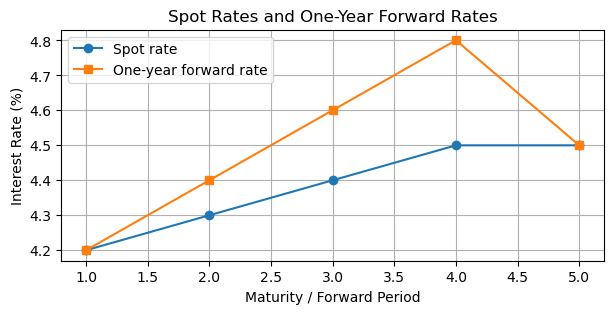

In [13]:
plt.figure(figsize=(7, 3))
plt.plot(annual_maturities, annual_spot_rates * 100, marker='o', label='Spot rate')
plt.plot(annual_maturities, np.array(forward_rates) * 100, marker='s', label='One-year forward rate')
plt.xlabel('Maturity / Forward Period')
plt.ylabel('Interest Rate (%)')
plt.title('Spot Rates and One-Year Forward Rates')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Remember that forward rates are rates implied by today's term structure under
# the no-arbitrage condition; they are not automatically forecasts.
# Another exercise: 1-year spot = 4%, 2-year spot = 5%.
r1_ex = 0.04
r2_ex = 0.05
forward_ex = (1 + r2_ex)**2 / (1 + r1_ex) - 1
print("\nFORWARD RATE EXERCISE")
print("1-year forward rate beginning in year 1:", forward_ex * 100, "%")


FORWARD RATE EXERCISE
1-year forward rate beginning in year 1: 6.009615384615374 %


In [15]:
# General forward rate between T1 and T2, continuous compounding:
# exp(r2*T2) = exp(r1*T1)exp(f(T1,T2)*(T2-T1))
def forward_rate_cts(r1, T1, r2, T2):
    return (r2*T2- r1*T1)/(T2-T1)

In [16]:
maturity = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30]
rates = [0.040, 0.041, 0.042, 0.043, 0.044,
    0.045, 0.046, 0.047, 0.048, 0.048]


In [17]:
# Initialize list with the first spot rate (forward rate for [0, T0] equals spot rate r0)
forward_rates_cts = [rates[0]]
for i in range(1, len(maturity)):
    f_i = forward_rate_cts(rates[i-1], maturity[i-1], rates[i], maturity[i])
    forward_rates_cts.append(f_i)
forward_rates_cts

[0.04,
 0.042,
 0.043000000000000003,
 0.04399999999999999,
 0.04600000000000001,
 0.046499999999999986,
 0.048500000000000015,
 0.04933333333333332,
 0.049,
 0.048]

In [18]:
# Output results mapped to intervals
for i in range(len(maturity)):
    if i == 0:
        print(f"f(0, {maturity[0]}): {forward_rates_cts[0]:.4f}")   
    #The f before a string creates a formatted string literal
    #It allows you to embed Python expressions directly inside a text string 
    #by wrapping them in curly braces {}.    
    #.4f controls the number of decimals
    else:
        print(f"f({maturity[i-1]}, {maturity[i]}): {forward_rates_cts[i]:.4f}")

f(0, 0.25): 0.0400
f(0.25, 0.5): 0.0420
f(0.5, 1): 0.0430
f(1, 2): 0.0440
f(2, 3): 0.0460
f(3, 5): 0.0465
f(5, 7): 0.0485
f(7, 10): 0.0493
f(10, 20): 0.0490
f(20, 30): 0.0480


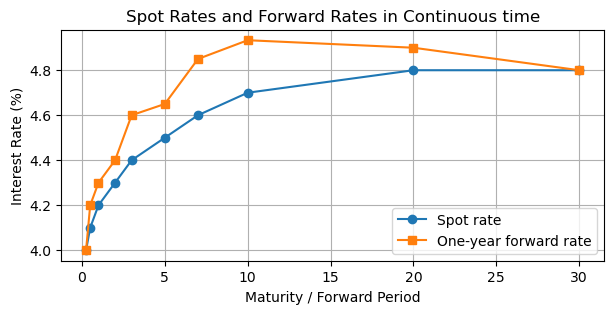

In [19]:
plt.figure(figsize=(7, 3))
plt.plot(maturity, np.array(rates) * 100, marker='o', label='Spot rate')
plt.plot(maturity, np.array(forward_rates_cts) * 100, marker='s', label='One-year forward rate')
plt.xlabel('Maturity / Forward Period')
plt.ylabel('Interest Rate (%)')
plt.title('Spot Rates and Forward Rates in Continuous time')
plt.legend()
plt.grid(True)
plt.show()